# 피부 자극성 예측 — 데이터 파이프라인

> AI머신러닝 (2026-1) 기말 개인 프로젝트 · 1/2

NTP ICE 공개 데이터로 학습 데이터셋을 만들고, 분자 구조에서 feature를 계산해 저장하는 과정입니다.
전체 설명은 저장소 README를 참고하세요.


## ▶ 0. 환경 설정 및 데이터 로드

In [18]:
# -- 표준 라이브러리 --
import warnings
# -- 데이터 처리 --
import numpy as np
import pandas as pd
# -- 시각화 --
import matplotlib.pyplot as plt
import seaborn as sns
# -- 화학 정보(RDKit): SMILES 파싱·salt 제거·descriptor/fingerprint --
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem, SaltRemover, rdFingerprintGenerator
# -- 화학 공간 시각화 보조 (sklearn) --
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler



# 시각화 기본값 (마이너스 기호 깨짐 방지)
plt.rcParams['axes.unicode_minus'] = False
# 경고 숨김
warnings.filterwarnings('ignore')

In [19]:
### 0. 데이터 로드 (필요한 sheet만)
FILE_SKIN = 'skin_irritation.xlsx'
df_invitro  = pd.read_excel(FILE_SKIN, sheet_name='Data_invitro')
df_invivo   = pd.read_excel(FILE_SKIN, sheet_name='Data_invivo')

# 규모 파악
print(f'Data_invitro {df_invitro.shape}')
print(f'Data_invivo  {df_invivo.shape}')

Data_invitro (6259, 21)
Data_invivo  (2058, 25)


#📌 `skin_irritation`을 베이스 데이터셋으로 선택한 이유 
- 수업에서 다룬 데이터이기 때문에 각 단계를 더욱 안정적이게 진행할 수 있다. 
- In Vivo 데이터는 다양한 Endpoint를 가지기 때문에(참고-1) 어떤 이진 라벨을 만들지에 대한 다양한 선택지가 존재한다. (이 작업에선 공식 기준을 따름)
- **In Vivo + In Vitro** 두 시트를 한 파일에 담고 있어, 동일 화합물에 대한 신뢰도가 다른 다양한 시험법을 확인할 수 있다. 이는 신뢰도 순서에 따라 데이터를 점진적으로 통합하는 이어질 3단계의 전처리(Human + Rabbit + In Vitro)를 통해 활용했다.

In [20]:
# (참고-1) 어떤 endpoint가 있는지
print('[invivo] Endpoint 분포')
print(df_invivo['Endpoint'].value_counts())

[invivo] Endpoint 분포
Endpoint
EPA classification            1799
Qualitative classification      90
Positive reaction               90
GHS classification              79
Name: count, dtype: int64


## ▶ 1. 데이터 전처리
- **Step 1** - Human In Vivo 단독 
- **Step 2** - Human + Rabbit In Vivo 
- **Step 3** - In Vitro 추가

In [21]:
# 라벨 매핑 후 중복/결측 정제
def remove_label_conflicts(df, key='Chemical_Name', label='label'):
    """한 화합물에 0/1이 둘 다 달리면(라벨 충돌) 해당 화합물 자체를 제거(가장 안전)"""
    nuniq = df.groupby(key)[label].nunique()  # 화합물별 라벨 종류 수
    conflicts = nuniq[nuniq > 1].index        # 2종 이상 = 충돌
    if len(conflicts):
        print(f'  · 라벨 충돌 {len(conflicts)}건 제거')
    return df[~df[key].isin(conflicts)].copy()

def dedup_and_drop_nan_smiles(df, key='Chemical_Name', smiles='SMILES'):
    """화합물명 중복 제거 + SMILES 결측 제거"""
    df = df.drop_duplicates(subset=key, keep='first').copy()
    df = df.dropna(subset=[smiles]).copy()
    return df

#📌 `Step 1` - human in vivo부터 시작한 이유

- 사람을 대상으로 한 임상 데이터이므로(신뢰도가 가장 높음) 첫 단계에서 시도해본다.

In [22]:
### Step 1: Human In Vivo 단독
print('▶ Step 1: Human In Vivo')
df_human = df_invivo[(df_invivo['Mixture']=='Chemical') & (df_invivo['Species']=='Human')].copy()

# Qualitative : 등급 없음(Not Classified)이면 0, 나머지 1
df_qc = df_human[df_human['Endpoint']=='Qualitative classification'].copy()
df_qc['label'] = 0
df_qc.loc[df_qc['Response']!='Not classified', 'label'] = 1

# Positive reaction : 양성 0건이면 0, 1건 이상이면 1
df_pr = df_human[df_human['Endpoint']=='Positive reaction'].copy()
df_pr['label'] = 0
df_pr.loc[df_pr['Response']!='0', 'label'] = 1

# 두 endpoint 합친 뒤 → 라벨 충돌 제거 → 중복/결측 처리
df_human_total = pd.concat([df_qc, df_pr], ignore_index=True)
df_human_total = remove_label_conflicts(df_human_total)
df_human_clean = dedup_and_drop_nan_smiles(df_human_total)
print(f'  · 결과: {df_human_clean.shape}, label 분포={df_human_clean["label"].value_counts().to_dict()}')

▶ Step 1: Human In Vivo
  · 라벨 충돌 16건 제거
  · 결과: (81, 26), label 분포={0: 56, 1: 25}


#📌 `Step 2` - Rabbit을 추가하는 이유
- **⚠️ Step 1의 결과가 81(180→81)개로 적어, 과적합 위험이 있다.** 
- Rabbit은 Species 분포(참고-2)에서 1878행으로 절대 다수라, 통계적으로 의미 있는 양을 확보할 수 있다. 또한 Draize test(토끼 피부 자극 시험)는 GHS·EPA가 채택한 공식 동물 모델이기 때문에 데이터 신뢰도가 높다.

In [23]:
# (참고-2) 어떤 Species가 있는지
print('[invivo] Species 분포')
print(df_invivo['Species'].value_counts())

[invivo] Species 분포
Species
Rabbit    1878
Human      180
Name: count, dtype: int64


In [24]:
### Step 2: Human + Rabbit In Vivo
print('▶ Step 2: Human + Rabbit In Vivo')
df_rabbit = df_invivo[(df_invivo['Mixture']=='Chemical') & (df_invivo['Species']=='Rabbit')].copy()

# EPA: 1·2·3 = 자극(1), 4 = 비자극(0)
df_epa = df_rabbit[df_rabbit['Endpoint']=='EPA classification'].copy()
df_epa['label'] = 0
df_epa.loc[df_epa['Response'].isin([1, 2, 3]), 'label'] = 1

# GHS: 1A·1B·1C = 자극(1), 그 외 = 비자극(0)
df_ghs = df_rabbit[df_rabbit['Endpoint']=='GHS classification'].copy()
df_ghs['label'] = 0
df_ghs.loc[df_ghs['Response'].isin(['1A', '1B', '1C', '1B/1C']), 'label'] = 1

# 두 endpoint 합친 뒤 → 라벨 충돌 제거 → 중복/결측 처리
df_rabbit_total = pd.concat([df_epa, df_ghs], ignore_index=True)
df_rabbit_total = remove_label_conflicts(df_rabbit_total)
df_rabbit_clean = dedup_and_drop_nan_smiles(df_rabbit_total)

# Human 우선: 앞에 두고(keep='first') → 충돌 시 Human 라벨 생존
"""모델이 최종적으로 예측할 대상이 사람이므로
   Human과 Rabbit이 겹칠 때 Human 라벨을 우선시한다."""
df_invivo_final = pd.concat([df_human_clean, df_rabbit_clean], ignore_index=True)
df_invivo_final = df_invivo_final.drop_duplicates(subset='Chemical_Name', keep='first').copy()
print(f'  · 결과: {df_invivo_final.shape}, label 분포={df_invivo_final["label"].value_counts().to_dict()}')

▶ Step 2: Human + Rabbit In Vivo
  · 결과: (138, 26), label 분포={0: 76, 1: 62}


#📌 `Step 3` - In Vitro까지 추가하는 이유
- 데이터 양과 다양성 보강 (이때 In Vitro의 Endpoint 중 "Call"만이 활성/비활성 최종 판정이므로 곧바로 이진 라벨로 쓸 수 있는 "Call"을 사용) (참고-3) 

In [25]:
# (참고-3) 어떤 Endpoint 가 있는지
print('[invitro] Endpoint 분포')
print(df_invitro['Endpoint'].value_counts())
print('\n[invitro] Call 분포')
print(df_invitro[df_invitro['Endpoint']=='Call']['Response'].value_counts())

[invitro] Endpoint 분포
Endpoint
Call                       2596
Viability                  1262
Viability (3 minutes)       690
Viability (60 minutes)      686
Viability (240 minutes)     296
ET50                        213
Breakthrough Time           207
TER                         133
Viability (18 hours)         44
Call (18 hours)              44
Viability (42 hours)         44
Call (42 hours)              44
Name: count, dtype: int64

[invitro] Call 분포
Response
Active          1409
Inactive        1166
Incompatible      21
Name: count, dtype: int64


In [26]:
### Step 3: In Vitro 추가
print('▶ Step 3: In Vivo + In Vitro(Call)')

# Call 행만 추출 → 이진 라벨 매핑
df_vit = df_invitro[df_invitro['Endpoint']=='Call'].copy()
df_vit['label'] = df_vit['Response'].map({'Active': 1, 'Inactive': 0})
# 이미 이진 → 변환 손실 없음
df_vit = df_vit.dropna(subset=['label']).copy()
df_vit['label'] = df_vit['label'].astype(int)
df_vit = remove_label_conflicts(df_vit)
df_vit = dedup_and_drop_nan_smiles(df_vit)

# In Vivo 우선: 앞에 두고 keep='first'
"""신뢰도 In Vivo > In Vitro"""
df_skin_all = pd.concat([df_invivo_final, df_vit], ignore_index=True)
df_skin_all = df_skin_all.drop_duplicates(subset='Chemical_Name', keep='first').copy()
df_skin_all['Source'] = 'skin_irritation'
print(f'  · 최종 skin_irritation 통합: {df_skin_all.shape}, label={df_skin_all["label"].value_counts().to_dict()}')

▶ Step 3: In Vivo + In Vitro(Call)
  · 라벨 충돌 62건 제거
  · 최종 skin_irritation 통합: (279, 27), label={1: 148, 0: 131}


## ▶ 2. SMILES 표준화

In [27]:
_remover = SaltRemover.SaltRemover()

def standardize_smiles(smi):
    """(cleaned_smiles, log) 반환. 표준화 실패면 cleaned_smiles=None."""
    if not isinstance(smi, str) or pd.isna(smi):
        return None, 'invalid'
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None, 'parse_error'
    stripped = _remover.StripMol(mol)                 # salt 제거 → 활성 성분만
    cleaned = Chem.MolToSmiles(stripped)              # canonical 형태로 통일
    if not cleaned or not any(a.GetSymbol()=='C' for a in stripped.GetAtoms()):
        return None, 'inorganic'                      # 탄소 없음 = 무기물 제외
    if '.' in cleaned:                    
        return None, 'mixture'                        # 점(.) = 혼합물 제외
    return cleaned, ('salt_removed' if cleaned != smi else 'kept')

def add_cleaned_smiles(df, smiles_col='SMILES'):
    pairs = df[smiles_col].apply(standardize_smiles)
    df = df.copy()
    df['Cleaned_SMILES'] = [p[0] for p in pairs]
    df['Standardize_Log'] = [p[1] for p in pairs]     # 제거 사유 통계용
    return df

df_skin_all = add_cleaned_smiles(df_skin_all)
print('표준화 로그 분포 (skin_irritation):')
print(df_skin_all['Standardize_Log'].value_counts())

# canonical SMILES 기준 중복 제거(표기만 다른 동일 분자 제거)
df_skin_std = df_skin_all.dropna(subset=['Cleaned_SMILES']).copy()
df_skin_std = df_skin_std.drop_duplicates(subset='Cleaned_SMILES', keep='first').copy()
print(f'\n표준화 후 유효 화합물: {df_skin_std.shape[0]}개')

표준화 로그 분포 (skin_irritation):
Standardize_Log
salt_removed    134
kept             90
inorganic        47
mixture           8
Name: count, dtype: int64

표준화 후 유효 화합물: 181개


[06:39:29] WARNING: not removing hydrogen atom without neighbors
[06:39:29] WARNING: not removing hydrogen atom without neighbors
[06:39:29] WARNING: not removing hydrogen atom without neighbors
[06:39:29] WARNING: not removing hydrogen atom without neighbors
[06:39:29] WARNING: not removing hydrogen atom without neighbors


## ▶ 3. 외부 데이터 추가

#📌 `skin_sensitization`을 추가하는 이유
- 관심 분야와의 연결 : 감작(알레르기성 피부 반응)은 자극과 함께 가장 흔한 피부 이상 반응이기도 하고, 동일 파이프라인을 다른 피부 Endpoint로 확장해보고 싶은 마음에 선택했다.
- 같은 피부 도메인 : 기전은 다르나, 모두 피부에 직접 작용하는 화합물의 반응성과 연관돼 화학 구조 공간이 겹친다.
- 따라서 같은 피부 도메인의 데이터로 규모와 다양성을 보완한다.

In [28]:
### 3. 외부 데이터 추가
print('▶ Skin Sensitization (in vitro Call) 통합')

# 데이터 로드
F_SENS = 'skin_sensitization.xlsx'
sens_it = pd.read_excel(F_SENS, sheet_name='Data_invitro')

# Step 3과 동일한 논리: Call(최종 활성/비활성 판정)만 사용 → 이진 라벨
df_sens = sens_it[sens_it['Endpoint']=='Call'].copy()
df_sens['label'] = df_sens['Response'].map({'Active': 1, 'Inactive': 0})  # 이미 이진
df_sens = df_sens.dropna(subset=['label']).copy()
df_sens['label'] = df_sens['label'].astype(int)

# 충돌 제거 → 중복/결측 정제 → SMILES 표준화(동일 규칙)
df_sens = remove_label_conflicts(df_sens)
df_sens = dedup_and_drop_nan_smiles(df_sens)
df_sens = add_cleaned_smiles(df_sens)
df_sens = df_sens.dropna(subset=['Cleaned_SMILES']).copy()
df_sens = df_sens.drop_duplicates(subset='Cleaned_SMILES', keep='first').copy()
df_sens['Source'] = 'skin_sensitization'
print(f'  · sensitization: {df_sens.shape}, label={df_sens["label"].value_counts().to_dict()}')

▶ Skin Sensitization (in vitro Call) 통합
  · 라벨 충돌 142건 제거
  · sensitization: (93, 33), label={1: 70, 0: 23}


In [29]:
### 3. skin_irritation + sensitization (skin 우선) 
cols = ['Chemical_Name', 'SMILES', 'Cleaned_SMILES', 'label', 'Source']

# skin을 앞에 두고 Cleaned_SMILES 기준 keep='first' → 겹치면 skin 라벨 생존
df_merged = pd.concat([df_skin_std[cols], df_sens[cols]], ignore_index=True)
df_merged = df_merged.drop_duplicates(subset='Cleaned_SMILES', keep='first').copy()

print(f'최종 통합: {df_merged.shape}, label={df_merged["label"].value_counts().to_dict()}')
print(f'Source 구성: {df_merged["Source"].value_counts().to_dict()}')

최종 통합: (266, 5), label={1: 156, 0: 110}
Source 구성: {'skin_irritation': 181, 'skin_sensitization': 85}


## ▶ 4. 시각화

In [30]:
def safe_mw(smi):
    m = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
    return Descriptors.MolWt(m) if m else np.nan

df_merged['MW']      = df_merged['Cleaned_SMILES'].map(safe_mw)
df_merged['MolLogP'] = df_merged['Cleaned_SMILES'].map(
    lambda s: Descriptors.MolLogP(Chem.MolFromSmiles(s)) if Chem.MolFromSmiles(s) else np.nan
)

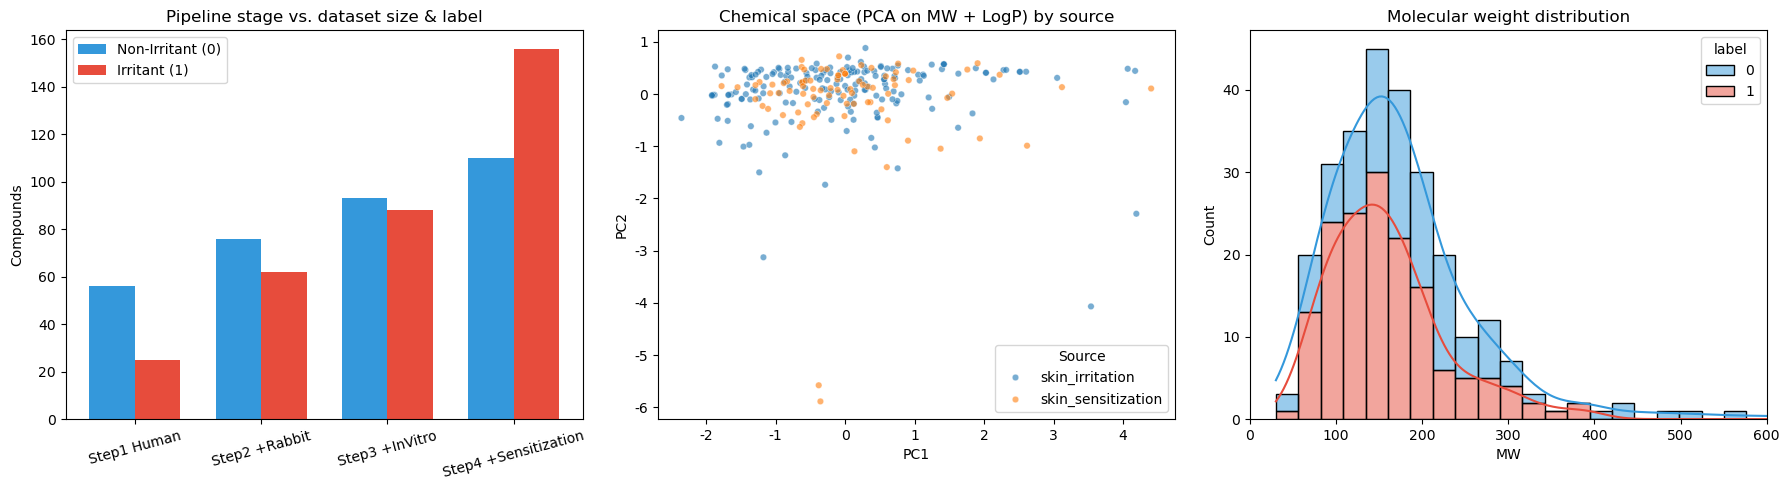

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (1) 단계별 데이터 크기 + 라벨 균형
ax = axes[0]
stage_dfs = {
    'Step1 Human':          df_human_clean,
    'Step2 +Rabbit':        df_invivo_final,
    'Step3 +InVitro':       df_skin_std,
    'Step4 +Sensitization': df_merged,
}
neg = [(d['label']==0).sum() for d in stage_dfs.values()]
pos = [(d['label']==1).sum() for d in stage_dfs.values()]
x = np.arange(len(stage_dfs))
ax.bar(x-0.18, neg, 0.36, label='Non-Irritant (0)', color='#3498db')
ax.bar(x+0.18, pos, 0.36, label='Irritant (1)',     color='#e74c3c')
ax.set_xticks(x); ax.set_xticklabels(list(stage_dfs.keys()), rotation=15)
ax.set_ylabel('Compounds'); ax.set_title('Pipeline stage vs. dataset size & label')
ax.legend()

# (2) PCA on (MW, MolLogP) coloured by Source
ax = axes[1]
small = df_merged.dropna(subset=['MW', 'MolLogP']).copy()
Xs = StandardScaler().fit_transform(small[['MW', 'MolLogP']])
p2 = PCA(n_components=2).fit_transform(Xs)
small['PC1'], small['PC2'] = p2[:, 0], p2[:, 1]
sns.scatterplot(data=small, x='PC1', y='PC2', hue='Source', alpha=0.6, ax=ax, s=22)
ax.set_title('Chemical space (PCA on MW + LogP) by source')

# (3) MW 분포 by label
ax = axes[2]
sns.histplot(
    data=df_merged.dropna(subset=['MW']), x='MW', hue='label', kde=True,
    palette={0:'#3498db', 1:'#e74c3c'}, multiple='stack', ax=ax,
)
ax.set_xlim(0, 600); ax.set_title('Molecular weight distribution')

plt.tight_layout(); plt.show()   

#📌 `시각화 3종` 설명

1. `단계별 데이터 크기 + 라벨 균형 (bar)`
- **데이터 부족**이라는 한계 분석의 정량적 증거
- step 1 - 4 까지 막대가 점점 커짐
- +) step 4 (외부 데이터 추가) : 자극(빨강) > 비자극(파랑) → ⚠️ `sensitization` 데이터의 양성 치우침

2. `PCA on (MW, MolLogP) by Source (scatter)`
- 원본 vs 추가 데이터의 화학 공간 비교 (추가 데이터의 정당성)
- 거의 겹쳐 있기 때문에 **도메인이 가까워 화학 공간이 겹친다**는 근거 검증

3. `Molecular Weight 분포 (histogram)`
- 자극(1) vs 비자극(0) 화합물의 분자량 분포 (라벨이 단순 분자량으로 분리되는지)
- 거의 겹쳐 있기 때문에 분자량만으로는 자극 여부를 못 가른다. (다음 단계 : fingerprint 필요)

## ▶ 5. Descriptor & Fingerprint

#📌 `feature 4종`

- `2D Descriptors` : 분자량·소수성·극성 등 자극과 직접 연관된 성질
- `Morgan FP`      : 반응성 작용기
- `RDKit FP`       : 선형·사슬형 부분구조 (Morgan 보완)
- `MACCS Keys`     : 해석이 쉬운 구조 특성

이 단계에서는 4종을 후보로 계산해두고, 모델링 단계에서 성능을 비교해 선택한다.

In [32]:
### 5. Descriptor & Fingerprint
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
rdkit_gen  = rdFingerprintGenerator.GetRDKitFPGenerator(fpSize=2048)

def calc_descriptors(smi):
    """단일 SMILES에 대해 2D descriptor dict 반환."""
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    return Descriptors.CalcMolDescriptors(mol)     # 전체 descriptor 일괄 계산

def calc_fingerprints(smi):
    """세 가지 fingerprint를 dict(prefix별 비트 분리)로 반환."""
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    out = {}
    # Morgan_/RDKitFP_/MACCS_로 출처 구분
    for i, b in enumerate(morgan_gen.GetFingerprint(mol)):
        out[f'Morgan_{i}'] = int(b)
    for i, b in enumerate(rdkit_gen.GetFingerprint(mol)):
        out[f'RDKitFP_{i}'] = int(b)
    for i, b in enumerate(AllChem.GetMACCSKeysFingerprint(mol)):
        out[f'MACCS_{i}'] = int(b)
    return out

# 2D descriptor 계산 (표준화된 Cleaned_SMILES 기준으로 계산)
print('▶ 2D descriptors 계산 중…')
desc_rows = df_merged['Cleaned_SMILES'].apply(calc_descriptors)
df_desc = pd.DataFrame(list(desc_rows))

# fingerprint 계산
print('▶ Fingerprints (Morgan + RDKit + MACCS) 계산 중…')
fp_rows = df_merged['Cleaned_SMILES'].apply(calc_fingerprints)
df_fp = pd.DataFrame(list(fp_rows))

# 합치기
df_final = pd.concat([
    df_merged[['Chemical_Name', 'SMILES', 'Cleaned_SMILES', 'Source', 'label']].reset_index(drop=True),
    df_desc.reset_index(drop=True),
    df_fp.reset_index(drop=True),
], axis=1)

print(f'최종 feature 테이블: {df_final.shape}')
print(f'  - 메타 컬럼 5  +  descriptor {df_desc.shape[1]}  +  fingerprint {df_fp.shape[1]}')

▶ 2D descriptors 계산 중…
▶ Fingerprints (Morgan + RDKit + MACCS) 계산 중…
최종 feature 테이블: (266, 4485)
  - 메타 컬럼 5  +  descriptor 217  +  fingerprint 4263


## 💾 6. 최종 데이터셋 저장 & 검증

In [33]:
OUT = 'final_dataset_descriptors.csv'
df_final.to_csv(OUT, index=False)
print(f'저장 완료: {OUT}  ({df_final.shape[0]}행 × {df_final.shape[1]}열)')

# 빠른 검증 — 메타 + 핵심 descriptor 일부만
preview_cols = ['Chemical_Name', 'Cleaned_SMILES', 'Source', 'label', 'MolWt', 'MolLogP', 'TPSA']
df_final[[c for c in preview_cols if c in df_final.columns]].head(10)

저장 완료: final_dataset_descriptors.csv  (266행 × 4485열)


,Chemical_Name,Cleaned_SMILES,Source,label,MolWt,MolLogP,TPSA
0,Propylene glycol,CC(O)CO,skin_irritation,0,76.095,-0.6405,40.46
1,Heptanal,CCCCCCC=O,skin_irritation,1,114.188,2.1557,17.07
2,Isopropyl myristate,CCCCCCCCCCCCCC(=O)OC(C)C,skin_irritation,0,270.457,5.6391,26.30
3,4-Methylthio benzaldehyde,CSc1ccc(C=O)cc1,skin_irritation,0,152.218,2.2210,17.07
4,Heptyl butyrate,CCCCCCCOC(=O)CCC,skin_irritation,0,186.295,3.3001,26.30
5,Hydroxycitronellal,COC(=O)c1ccccc1N=CCC(C)CCCC(C)(C)O,skin_irritation,0,305.418,4.1429,58.89
6,Methyl caproate,CCCCCC(=O)OC,skin_irritation,0,130.187,1.7397,26.30
7,1-(2-Isopropylphenyl)-1-phenyle- thane (Mixtur...,CC(C)c1ccccc1C(C)c1ccccc1,skin_irritation,0,224.347,4.9618,0.00
8,Benzyl salicylate,O=C(OCc1ccccc1)c1ccccc1O,skin_irritation,0,228.247,2.7492,46.53
9,Sodium dodecyl sulphate,CCCCCCCCCCCCOS(=O)(=O)[O-],skin_irritation,1,265.395,3.3841,66.43
